# Лабораторная работа 3. Кластеризация

Цель работы: изучить алгоритмы кластеризации, научиться оценивать качество разбиения данных на кластеры и интерпретировать результаты. Для работы взял Dry Bean Dataset (UCI): геометрические характеристики зёрен сухой фасоли, измеренные по фотографиям. Кластеризацию выполню двумя методами: K-means и EM-алгоритмом (Gaussian Mixture).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from sklearn.metrics.cluster import pair_confusion_matrix

sns.set_theme(style="whitegrid")
RS = 42

Подключил нужные библиотеки и зафиксировал random_state, чтобы результаты воспроизводились при повторном запуске.

In [2]:
df = pd.read_excel("Dry_Bean_Dataset.xlsx")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

Загрузил датасет. В нём 13611 объектов и 17 столбцов: 16 числовых признаков (площадь, периметр, длины осей, коэффициенты формы и т. д.) и текстовый столбец Class с семью сортами фасоли. Пропусков нет, во всех столбцах по 13611 значений. Class при кластеризации использовать не буду, он нужен только для внешней оценки в конце.

In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.28,29324.10,20420.00,36328.00,44652.00,61332.00,254616.00
Perimeter,13611.0,855.28,214.29,524.74,703.52,794.94,977.21,1985.37
MajorAxisLength,13611.0,320.14,85.69,183.60,253.30,296.88,376.50,738.86
MinorAxisLength,13611.0,202.27,44.97,122.51,175.85,192.43,217.03,460.20
AspectRation,13611.0,1.58,0.25,1.02,1.43,1.55,1.71,2.43
Eccentricity,13611.0,0.75,0.09,0.22,0.72,0.76,0.81,0.91
ConvexArea,13611.0,53768.20,29774.92,20684.00,36714.50,45178.00,62294.00,263261.00
EquivDiameter,13611.0,253.06,59.18,161.24,215.07,238.44,279.45,569.37
Extent,13611.0,0.75,0.05,0.56,0.72,0.76,0.79,0.87
Solidity,13611.0,0.99,0.00,0.92,0.99,0.99,0.99,0.99


Признаки лежат в очень разных масштабах: площадь и периметр измеряются десятками тысяч и сотнями, а ShapeFactor1 и ShapeFactor2 меньше 0,01. Без масштабирования расстояния определялись бы только крупными признаками. У Area максимум 254616 при медиане 44652, значит справа есть длинный хвост из очень крупных зёрен.

In [4]:
dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
dup, df.shape

(np.int64(68), (13543, 17))

Нашёл 68 полностью совпадающих строк и удалил их, осталось 13543 объекта. Повторы дают одним и тем же точкам лишний вес, поэтому для кластеризации их лучше не оставлять.

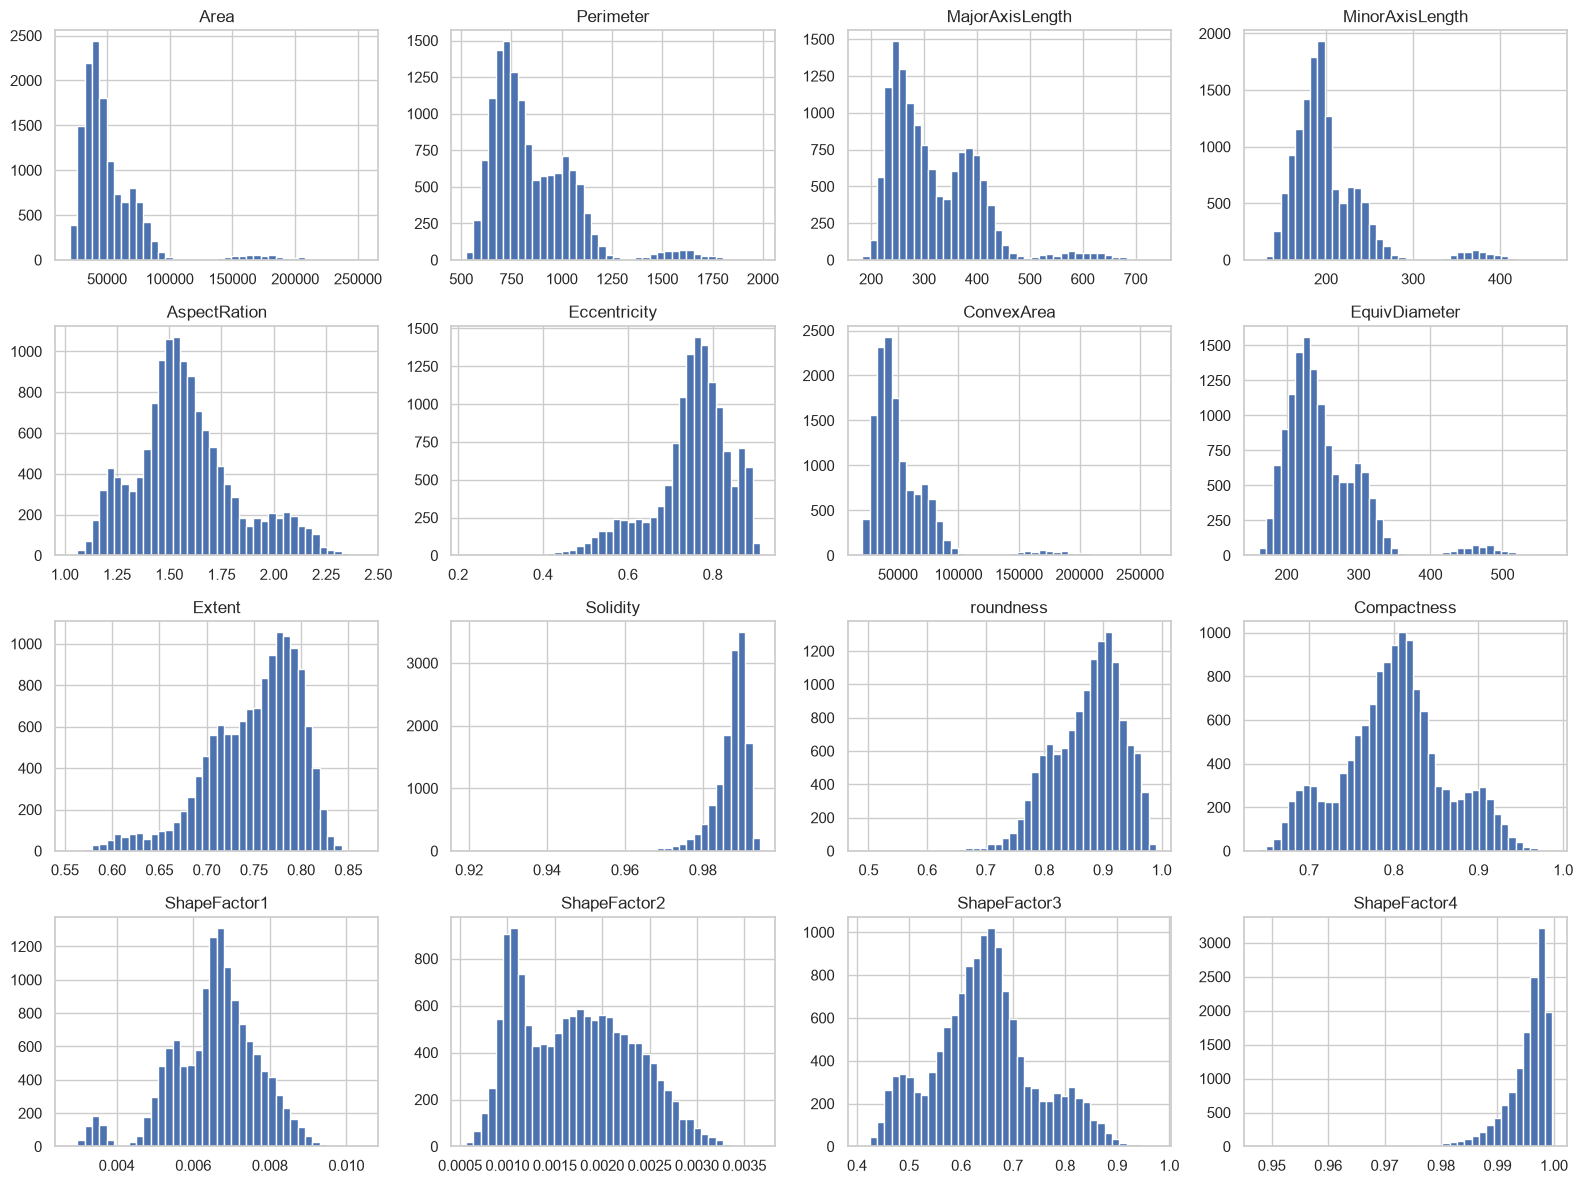

In [5]:
X = df.drop(columns="Class")
y = df["Class"]
X.hist(bins=40, figsize=(16, 12))
plt.tight_layout()
plt.show()

Распределения в основном не похожи на нормальные. Area, ConvexArea, Perimeter и MinorAxisLength скошены вправо и имеют отдельный небольшой горб в области больших значений, это крупные зёрна. Solidity и ShapeFactor4 скошены влево и прижаты к единице. У AspectRation, ShapeFactor2 и ShapeFactor3 заметно несколько вершин, то есть данные похожи на смесь нескольких групп. Ближе всего к нормальному выглядят Compactness и ShapeFactor1, у roundness небольшой левый хвост.

In [6]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
out_share = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).mean() * 100
pd.DataFrame({"skew": X.skew(), "outliers_%": out_share}).round(2)

,skew,outliers_%
Area,2.95,4.07
Perimeter,1.63,3.69
MajorAxisLength,1.37,2.80
MinorAxisLength,2.23,4.19
AspectRation,0.59,3.58
Eccentricity,-1.06,6.15
ConvexArea,2.94,4.05
EquivDiameter,1.95,3.88
Extent,-0.90,2.00
Solidity,-2.55,5.72


Асимметрия сильнее всего у Area и ConvexArea (около 3), ShapeFactor4 (-2,76) и Solidity (-2,55). Доля выбросов по правилу 1,5 IQR ни в одном признаке не превышает 6,2 %: больше всего у Eccentricity (6,15 %), Solidity (5,72 %) и ShapeFactor4 (5,61 %). Правые выбросы по размерам относятся к настоящей группе крупных зёрен, а не к ошибкам измерения, поэтому удалять их не стал, иначе пропала бы целая группа. Чувствительность K-means к таким точкам учту при интерпретации.

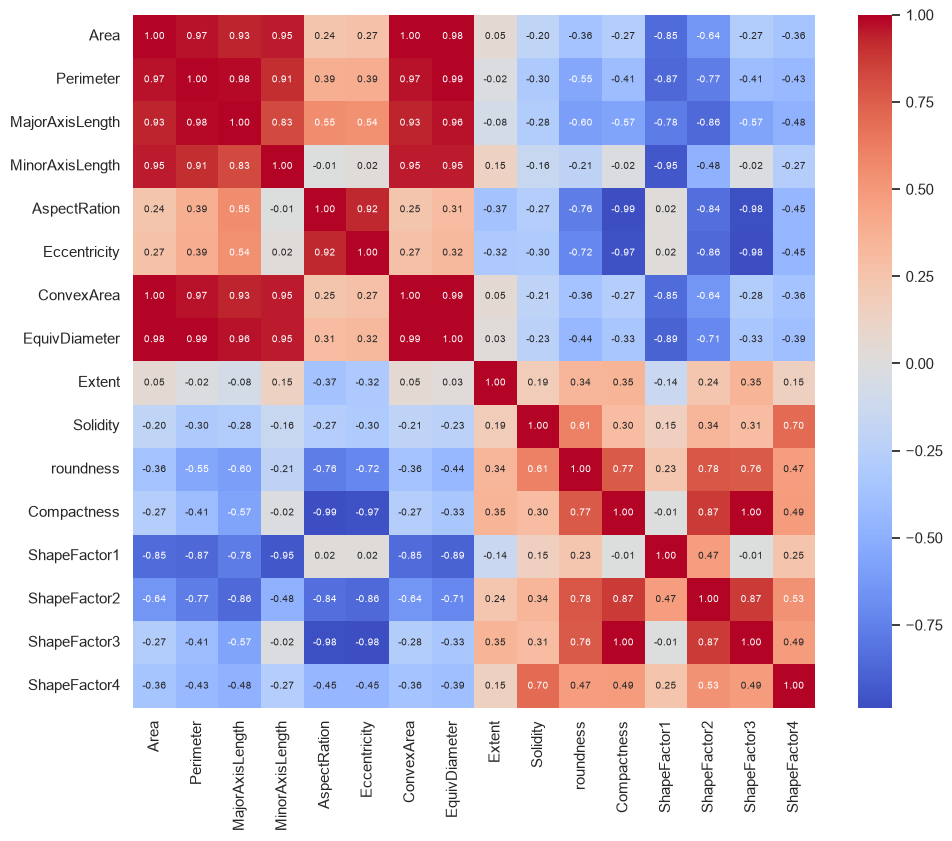

In [7]:
plt.figure(figsize=(11, 9))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.show()

На матрице корреляций видны две группы почти дублирующих друг друга признаков. Первая описывает размер зерна: Area, Perimeter, ConvexArea, EquivDiameter, MajorAxisLength и MinorAxisLength, у большинства пар корреляция выше 0,95, а у Area и ConvexArea она равна 1,00. Вторая описывает форму: AspectRation, Eccentricity, Compactness и ShapeFactor3, корреляции 0,97-0,999. Если оставить всё, размер и вытянутость получат в евклидовом расстоянии завышенный вес.

In [8]:
X = X.drop(columns=["ConvexArea", "EquivDiameter", "Compactness"])
X.shape

(13543, 13)

Убрал ConvexArea (дублирует Area, r = 1,00), EquivDiameter (r = 0,985 с Area и 0,991 с Perimeter) и Compactness (r = 0,999 с ShapeFactor3). Осталось 13 признаков. Остальные коррелированные пары оставил, чтобы не потерять информацию о размере и форме зерна.

In [9]:
scaler = StandardScaler()
Xs = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
Xs.describe().loc[["mean", "std"]].round(2)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,Extent,Solidity,roundness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
mean,0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Стандартизировал признаки через StandardScaler: после преобразования у каждого среднее 0 и стандартное отклонение 1. Выбрал этот метод, потому что K-means и GMM работают с евклидовыми расстояниями и дисперсиями, значит признаки должны быть в одной шкале, а StandardScaler к тому же рекомендован в задании. Min-max нормализация здесь хуже: из-за длинных хвостов основная масса значений сжалась бы в узкий отрезок.

In [10]:
def hopkins(data, m=500, seed=RS):
    rng = np.random.default_rng(seed)
    data = np.asarray(data)
    idx = rng.choice(len(data), m, replace=False)
    uniform = rng.uniform(data.min(axis=0), data.max(axis=0), size=(m, data.shape[1]))
    nn = NearestNeighbors(n_neighbors=2).fit(data)
    w = nn.kneighbors(data[idx], return_distance=True)[0][:, 1]
    u = nn.kneighbors(uniform, return_distance=True)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())

round(hopkins(Xs), 3)

np.float64(0.948)

Статистика Хопкинса получилась 0,948. Для равномерно распределённых данных она около 0,5, а значение, близкое к 1, говорит о выраженной кластерной тенденции. Значит, данные не однородное облако и кластеризация здесь имеет смысл.

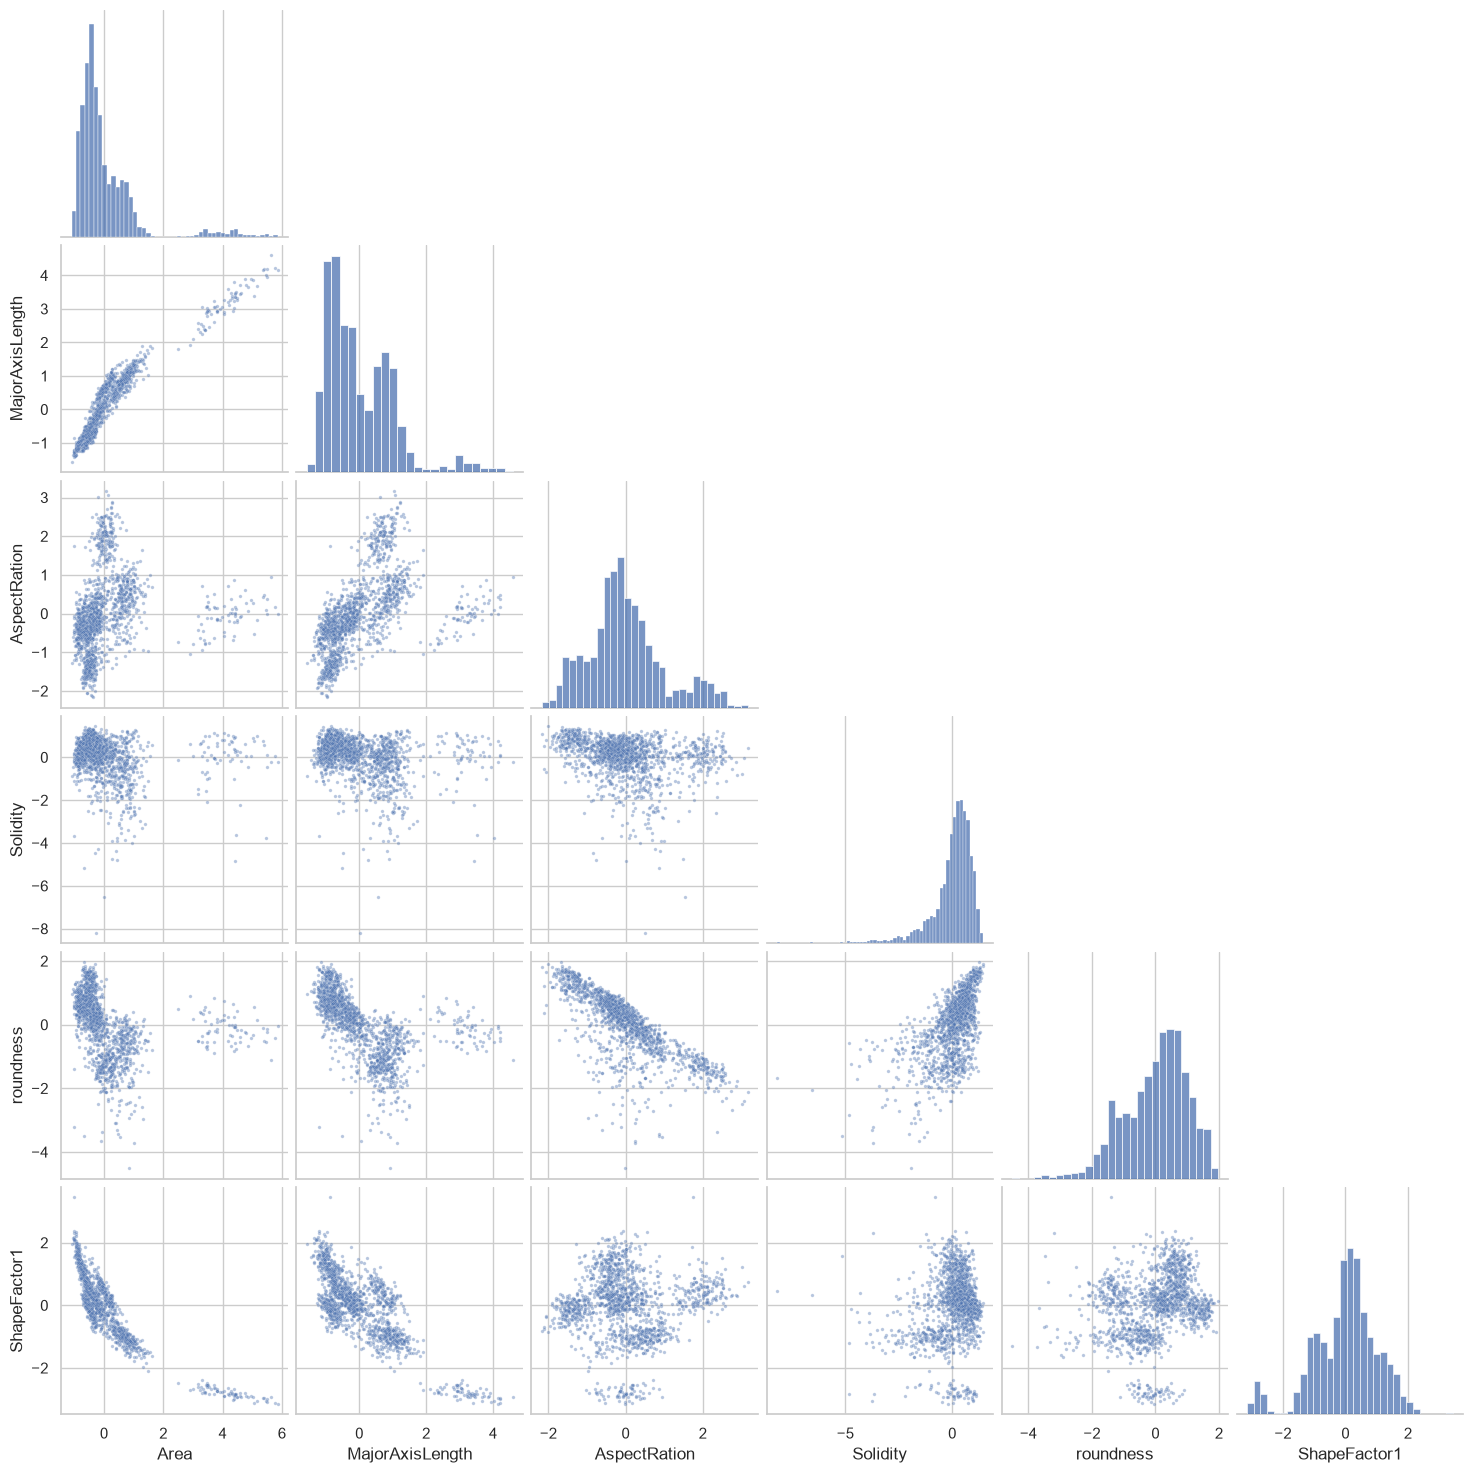

In [11]:
cols = ["Area", "MajorAxisLength", "AspectRation", "Solidity", "roundness", "ShapeFactor1"]
sns.pairplot(Xs[cols].sample(1500, random_state=RS), corner=True, plot_kws={"s": 6, "alpha": 0.4})
plt.show()

На матрице диаграмм рассеивания видно, что Area и MajorAxisLength связаны почти линейно. Отдельно от основной массы лежит небольшая компактная группа очень крупных зёрен. Основная масса неоднородна: на парах с AspectRation, roundness и ShapeFactor1 видно несколько плотных скоплений, которые частично перекрываются. Кластеры вытянутые, разного размера и плотности, чёткой границы между ними нет. Визуально предполагаю 3-4 кластера.

По такой структуре выбрал K-means как базовый метод и EM-алгоритм, который умеет описывать эллиптические кластеры разного размера и формы. DBSCAN не взял из-за разной плотности групп и их перекрытия. Иерархическую кластеризацию делать не стал из-за объёма данных: для 13543 объектов матрица расстояний содержит около 180 млн значений, а дендрограмма на таком числе точек нечитаема.

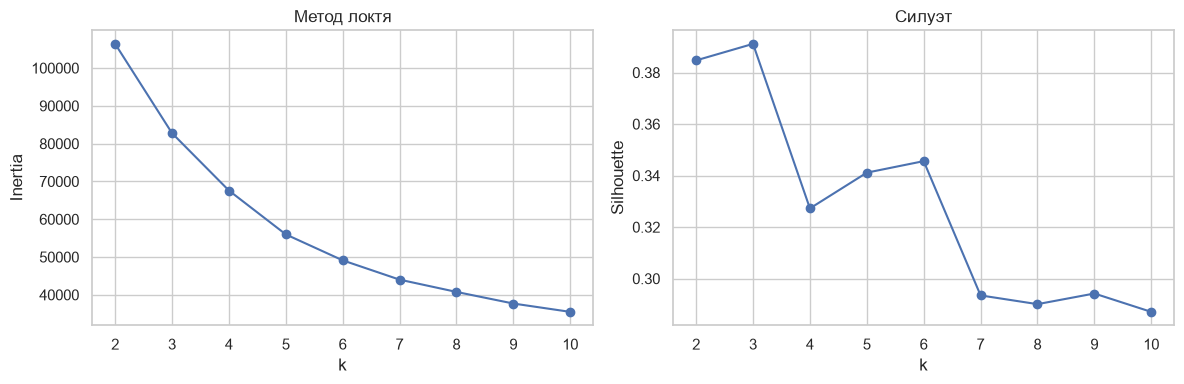

,k,inertia,silhouette
0,2,106395.308,0.385
1,3,82769.347,0.391
2,4,67590.486,0.327
3,5,55982.090,0.341
4,6,49116.356,0.346
5,7,44009.990,0.293
6,8,40761.200,0.290
7,9,37689.280,0.294
8,10,35483.748,0.287


In [12]:
ks = range(2, 11)
inertia, sil_km = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(Xs)
    inertia.append(km.inertia_)
    sil_km.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, "o-")
ax[0].set(xlabel="k", ylabel="Inertia", title="Метод локтя")
ax[1].plot(ks, sil_km, "o-")
ax[1].set(xlabel="k", ylabel="Silhouette", title="Силуэт")
plt.tight_layout()
plt.show()
pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil_km}).round(3)

Инерция убывает монотонно, чёткого излома нет, но после k = 3-4 кривая заметно выпрямляется (106395 при k = 2, 82769 при k = 3, 67590 при k = 4). Коэффициент силуэта максимален при k = 3 (0,391), при k = 2 почти такой же (0,385), дальше он падает до 0,327 при k = 4 и держится в районе 0,29-0,35. Оба метода согласуются с оценкой по диаграммам, поэтому для K-means взял k = 3.

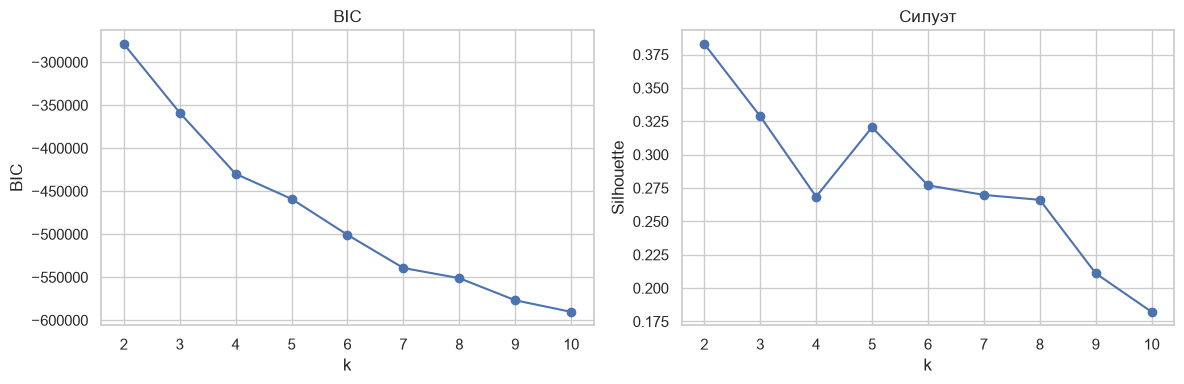

,k,BIC,silhouette
0,2,-278710.896,0.383
1,3,-358733.994,0.329
2,4,-429802.336,0.269
3,5,-458917.007,0.321
4,6,-500685.018,0.277
5,7,-539256.508,0.270
6,8,-551093.559,0.266
7,9,-576785.215,0.211
8,10,-590272.641,0.182


In [13]:
bic, sil_gm = [], []
for k in ks:
    gm = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=RS).fit(Xs)
    bic.append(gm.bic(Xs))
    sil_gm.append(silhouette_score(Xs, gm.predict(Xs)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, bic, "o-")
ax[0].set(xlabel="k", ylabel="BIC", title="BIC")
ax[1].plot(ks, sil_gm, "o-")
ax[1].set(xlabel="k", ylabel="Silhouette", title="Силуэт")
plt.tight_layout()
plt.show()
pd.DataFrame({"k": list(ks), "BIC": bic, "silhouette": sil_gm}).round(3)

У EM-алгоритма BIC уменьшается на всём диапазоне от 2 до 10 компонент и минимума не даёт: модель с полными ковариационными матрицами постоянно улучшает подгонку, потому что реальные группы не гауссовы. По BIC число компонент выбрать нельзя. Силуэт максимален при k = 2 (0,383), при k = 3 он равен 0,329. Чтобы сравнение методов было корректным, для EM тоже взял 3 компоненты.

In [14]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=RS).fit(Xs)
gm = GaussianMixture(n_components=K, covariance_type="full", n_init=3, random_state=RS).fit(Xs)
lab_km, lab_gm = km.labels_, gm.predict(Xs)

def jaccard(true, pred):
    (tn, fp), (fn, tp) = pair_confusion_matrix(true, pred)
    return tp / (tp + fp + fn)

def quality(labels):
    return {
        "Silhouette": silhouette_score(Xs, labels),
        "Calinski-Harabasz": calinski_harabasz_score(Xs, labels),
        "Davies-Bouldin": davies_bouldin_score(Xs, labels),
        "ARI": adjusted_rand_score(y, labels),
        "NMI": normalized_mutual_info_score(y, labels),
        "Jaccard": jaccard(y, labels),
    }

metrics = pd.DataFrame({"K-means": quality(lab_km), "EM (GMM)": quality(lab_gm)})
metrics.round(3)

,K-means,EM (GMM)
Silhouette,0.391,0.329
Calinski-Harabasz,7630.494,6285.799
Davies-Bouldin,0.950,1.418
ARI,0.296,0.325
NMI,0.483,0.474
Jaccard,0.311,0.325


Обучил оба метода с k = 3 и посчитал метрики. По внутренним метрикам лучше K-means: силуэт 0,391 против 0,329, индекс Калински-Харабаза 7630 против 6286, индекс Дэвиса-Болдина 0,950 против 1,418 (чем он меньше, тем лучше). Это ожидаемо, K-means напрямую минимизирует разброс внутри кластеров. Значения силуэта 0,3-0,4 говорят о слабо или умеренно выраженной структуре с перекрытием кластеров.

Внешние метрики относительно сортов у обоих методов невысокие: ARI 0,296 и 0,325, NMI 0,483 и 0,474, индекс Жаккара 0,311 и 0,325. EM немного лучше по ARI и Жаккару, NMI почти одинаковый. Низкие значения объясняются тем, что в данных семь сортов, а кластеров три, поэтому сорта неизбежно объединяются.

In [15]:
def centers_info(centers_scaled, labels):
    centers = pd.DataFrame(scaler.inverse_transform(centers_scaled), columns=X.columns)
    centers.insert(0, "size", np.bincount(labels))
    return centers

centers_info(km.cluster_centers_, lab_km).round(3).T

,0,1,2
size,524.000,7516.000,5503.000
Area,173264.840,37374.862,63003.713
Perimeter,1584.640,713.782,978.334
MajorAxisLength,592.701,259.799,375.978
MinorAxisLength,374.123,182.535,213.089
AspectRation,1.585,1.432,1.785
Eccentricity,0.770,0.699,0.818
Extent,0.777,0.760,0.734
Solidity,0.987,0.989,0.985
roundness,0.864,0.915,0.819


K-means выделил три группы. Нулевой кластер (524 объекта) это очень крупные зёрна: площадь около 173 тысяч, главная ось около 593. Первый кластер (7516 объектов) это мелкие округлые зёрна: площадь около 37 тысяч, roundness 0,915, ShapeFactor3 0,704. Второй (5503 объекта) это зёрна среднего размера (площадь около 63 тысяч) и более вытянутые: AspectRation 1,785, roundness 0,819. Группа крупных зёрен, которую я видел на диаграммах, оказалась в отдельном небольшом кластере.

In [16]:
centers_info(gm.means_, lab_gm).round(3).T

,0,1,2
size,7045.000,1630.000,4868.000
Area,36403.255,105964.769,59205.690
Perimeter,704.143,1239.149,943.014
MajorAxisLength,255.873,448.976,368.720
MinorAxisLength,180.793,288.338,204.472
AspectRation,1.425,1.553,1.816
Eccentricity,0.695,0.756,0.828
Extent,0.759,0.761,0.734
Solidity,0.989,0.984,0.986
roundness,0.916,0.821,0.830


Кластеры EM: первый (7045 объектов) это мелкие округлые зёрна, площадь около 36 тысяч, roundness 0,916, почти та же группа, что у K-means. Второй (1630 объектов) это крупные зёрна, площадь около 106 тысяч, главная ось 449. Третий (4868 объектов) это средние вытянутые зёрна, площадь около 59 тысяч, AspectRation 1,816. Главное отличие в крупных зёрнах: у K-means это совсем крупная группа из 524 объектов, а у EM в кластер вместе с самыми крупными попали крупные зёрна из соседней области, поэтому он втрое больше и его центр сместился вниз.

In [17]:
def compactness(centers_scaled, labels):
    d = np.linalg.norm(Xs.values - centers_scaled[labels], axis=1)
    return pd.Series(d).groupby(labels).mean()

pd.DataFrame({
    "K-means": compactness(km.cluster_centers_, lab_km),
    "EM (GMM)": compactness(gm.means_, lab_gm),
}).round(3)

,K-means,EM (GMM)
0,2.124,1.948
1,1.961,3.502
2,2.701,2.558


Среднее расстояние до центра (в стандартизованном пространстве) у K-means равно 2,12, 1,96 и 2,70, то есть кластеры сопоставимы по компактности, самый рыхлый второй. У EM компактность различается сильнее: 1,95, 3,50 и 2,56. Самый рыхлый второй кластер, в нём крупные зёрна с большим разбросом размеров.

In [18]:
pd.concat({
    "K-means": pd.DataFrame(squareform(pdist(km.cluster_centers_))),
    "EM (GMM)": pd.DataFrame(squareform(pdist(gm.means_))),
}, axis=1).round(2)

K-means             EM (GMM)            
        0     1     2        0     1     2
0    0.00  9.50  7.09     0.00  5.98  4.25
1    9.50  0.00  4.29     5.98  0.00  3.78
2    7.09  4.29  0.00     4.25  3.78  0.00

У K-means нулевой кластер далеко от остальных (расстояния между центрами 9,50 и 7,09), а первый и второй кластеры близки (4,29). Это согласуется с картинкой PCA ниже: крупные зёрна отделены хорошо, а основная масса делится на две перекрывающиеся части. У EM центры ближе друг к другу (5,98; 4,25; 3,78), потому что крупный кластер включает часть зёрен из соседней области.

In [19]:
rows = []
for k in ks:
    lab = KMeans(n_clusters=k, n_init=10, random_state=RS).fit_predict(Xs)
    q = quality(lab)
    rows.append({"k": k, **{m: q[m] for m in ["Silhouette", "Calinski-Harabasz", "Davies-Bouldin", "ARI"]}})
influence = pd.DataFrame(rows).set_index("k")
influence.round(3)

,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI
k,,,,
2,0.385,8866.144,1.112,0.279
3,0.391,7630.494,0.950,0.296
4,0.327,7242.426,0.976,0.440
5,0.341,7259.494,1.098,0.548
6,0.346,6997.354,1.032,0.536
7,0.293,6768.979,1.143,0.661
8,0.290,6418.064,1.131,0.635
9,0.294,6210.974,1.179,0.667
10,0.287,5957.049,1.191,0.584


Посмотрел, как число кластеров влияет на качество K-means. Силуэт максимален при k = 3, индекс Дэвиса-Болдина тоже минимален при k = 3 (0,950). Индекс Калински-Харабаза только убывает с ростом k, от 8866 при k = 2 до 5957 при k = 10, то есть по нему лучшим был бы k = 2. ARI растёт: 0,279 при k = 2, 0,440 при k = 4, 0,661 при k = 7, около 0,67 при k = 9 и снова падает до 0,584 при k = 10.

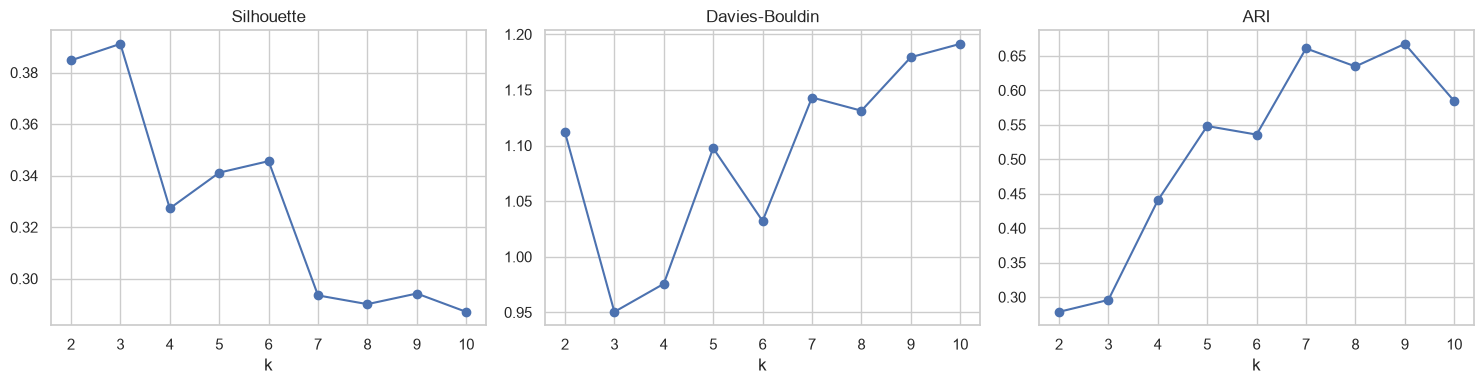

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, m in zip(ax, ["Silhouette", "Davies-Bouldin", "ARI"]):
    a.plot(influence.index, influence[m], "o-")
    a.set(xlabel="k", title=m)
plt.tight_layout()
plt.show()

Графики показывают расхождение внутренних и внешних метрик. Внутренние предпочитают 2-3 крупных кластера, а совпадение с реальными сортами достигается при 7-9 кластерах: при k = 7, равном числу сортов, ARI 0,661, хотя силуэт при этом снижается до 0,293. Причина в том, что сорта образуют не отдельные компактные скопления, а частично перекрывающиеся области (Seker, Dermason и Sira близки по размеру и форме, как и Barbunya, Cali и Horoz). Более детальное разбиение лучше совпадает с классами, но хуже по компактности и разделённости.

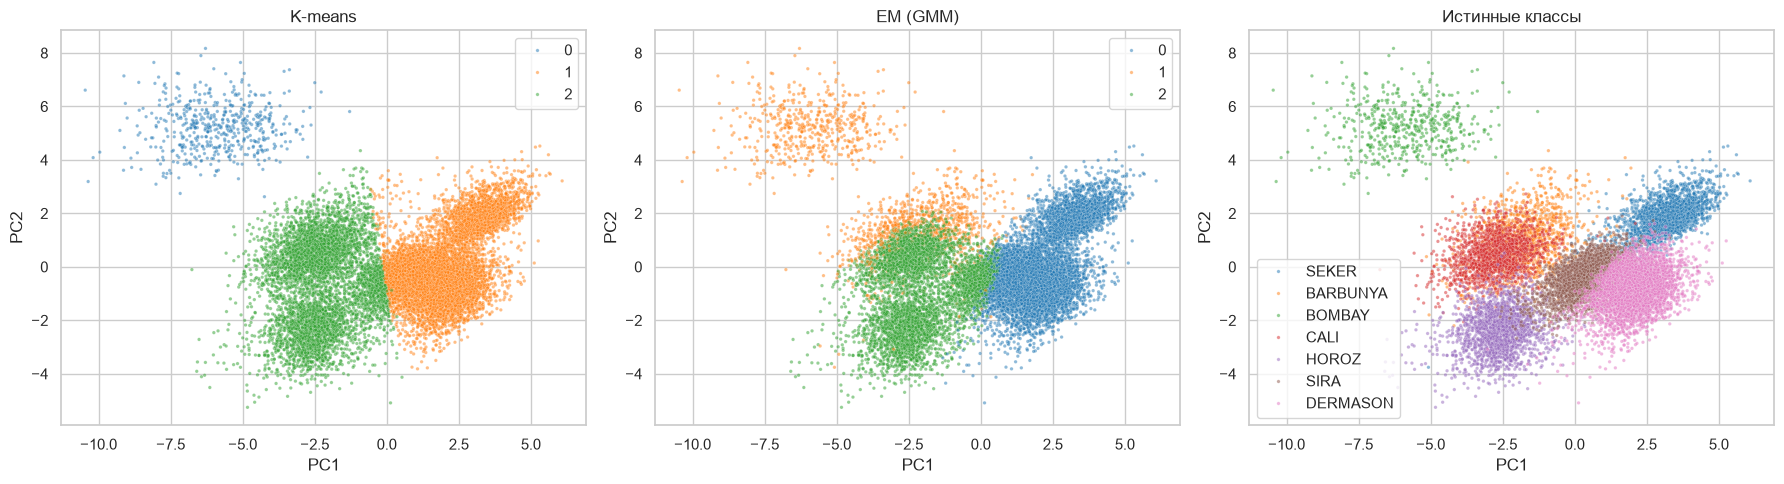

array([0.533, 0.252])

In [21]:
pca = PCA(n_components=2, random_state=RS)
Z = pca.fit_transform(Xs)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, lab, title in zip(ax, [lab_km, lab_gm, y.values], ["K-means", "EM (GMM)", "Истинные классы"]):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=lab, s=6, alpha=0.5, palette="tab10", ax=a)
    a.set(title=title, xlabel="PC1", ylabel="PC2")
plt.tight_layout()
plt.show()
pca.explained_variance_ratio_.round(3)

Две главные компоненты объясняют 78,5 % дисперсии (53,3 % и 25,2 %), поэтому плоскость PC1-PC2 неплохо передаёт структуру данных. Крупные зёрна (Bombay) лежат отдельно в левой верхней части. Остальные объекты образуют непрерывное облако без пустот между сортами, что объясняет невысокий силуэт. K-means делит облако примерно вертикальной линией около PC1 = 0. EM проводит границу похоже, но объединяет с Bombay верхнюю левую область облака, где лежат Barbunya.

In [22]:
pd.crosstab(y, lab_km)

col_0,0,1,2
Class,,,
BARBUNYA,1,93,1228
BOMBAY,522,0,0
CALI,1,8,1621
DERMASON,0,3490,56
HOROZ,0,17,1843
SEKER,0,2018,9
SIRA,0,1890,746


Кластер 0 у K-means почти целиком состоит из Bombay (522 из 524). Кластер 1 это Dermason (3490), Seker (2018) и большая часть Sira (1890). Кластер 2 это Barbunya (1228), Cali (1621), Horoz (1843) и часть Sira (746). То есть K-means разделил сорта на мелкие округлые, средние вытянутые и самые крупные, а внутри этих групп сорта не различил.

In [23]:
pd.crosstab(y, lab_gm)

col_0,0,1,2
Class,,,
BARBUNYA,17,842,463
BOMBAY,0,522,0
CALI,4,209,1417
DERMASON,3522,5,19
HOROZ,25,6,1829
SEKER,1976,33,18
SIRA,1501,13,1122


У EM кластер 0 это Dermason (3522), Seker (1976) и Sira (1501), кластер 2 это Horoz (1829), Cali (1417), Sira (1122) и часть Barbunya (463). Кластер 1 собрал Bombay (522) вместе с Barbunya (842) и Cali (209). Разбиение на мелкие и средние зёрна у двух методов почти совпадает, а Bombay в чистом виде EM выделить не удалось.

In [24]:
round(adjusted_rand_score(lab_km, lab_gm), 3)

0.73

ARI между разбиениями двух методов равен 0,73, то есть результаты в целом согласуются. Различие в основном в том, как поделены крупные зёрна и пограничная область в центре облака.

In [25]:
rng = np.random.default_rng(RS)
stab = {"K-means": [], "EM (GMM)": []}
for _ in range(10):
    idx = rng.choice(len(Xs), int(0.8 * len(Xs)), replace=False)
    sub = Xs.iloc[idx]
    stab["K-means"].append(adjusted_rand_score(lab_km, KMeans(K, n_init=10, random_state=int(rng.integers(1000))).fit(sub).predict(Xs)))
    stab["EM (GMM)"].append(adjusted_rand_score(lab_gm, GaussianMixture(K, n_init=3, random_state=int(rng.integers(1000))).fit(sub).predict(Xs)))
pd.DataFrame(stab).agg(["mean", "std", "min"]).round(3)

,K-means,EM (GMM)
mean,0.996,0.809
std,0.002,0.238
min,0.992,0.391


Для проверки устойчивости десять раз обучал модели на случайных 80 % выборки и сравнивал метки, которые они дают на всех данных, с исходным разбиением. K-means очень устойчив: средний ARI 0,996, стандартное отклонение 0,002, минимум 0,992. EM заметно менее устойчив: средний ARI 0,809, стандартное отклонение 0,238, минимум 0,391, то есть на отдельных подвыборках получается другое разбиение. Скорее всего, это связано с тем, что у модели с полными ковариационными матрицами есть несколько близких по правдоподобию решений, а группы в данных перекрываются.

Вывод. Я кластеризовал Dry Bean Dataset: после удаления 68 дубликатов осталось 13543 объекта, из 16 признаков оставил 13, убрав почти дублирующие по корреляции. Признаки стандартизировал, статистика Хопкинса 0,948 показала, что кластерная структура в данных есть. Диаграммы рассеивания показали вытянутые перекрывающиеся группы разного размера, поэтому выбрал K-means и EM-алгоритм.

По методу локтя и силуэту взял k = 3. K-means дал более высокие внутренние метрики (силуэт 0,391 против 0,329 у EM) и оказался очень устойчивым (средний ARI на подвыборках 0,996). EM чуть лучше совпал с сортами (ARI 0,325 против 0,296), но кластеры у него менее компактные, а разбиение заметно нестабильно (средний ARI 0,809 при минимуме 0,391). Разбиения двух методов в целом похожи, ARI между ними 0,73.

Получились три группы зёрен: мелкие округлые (Dermason, Seker и большая часть Sira), средние вытянутые (Barbunya, Cali, Horoz) и очень крупные (Bombay). Силуэт 0,3-0,4 говорит о том, что кластеры перекрываются и границы между ними размыты. Сорта фасоли по геометрии полностью не разделяются: чтобы приблизиться к семи классам, нужно брать 7-9 кластеров (ARI 0,661 при k = 7), но тогда ухудшаются внутренние метрики. Для грубого деления зёрен по размеру и форме лучше подходит K-means с k = 3.